# Prepare Environment

In [1]:
!pip install 'scanpy[leiden]'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 73.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 75.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 92.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.9 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing install

In [44]:
import scanpy as sc
import os
import pandas as pd
import numpy as np
import pickle as pkl
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.stats
import seaborn as sns

sc.settings.verbosity = 3

# Download and Prepare Data

In [2]:
!wget https://ftp.ncbi.nlm.nih.gov/geo/series/GSE72nnn/GSE72056/suppl/GSE72056_melanoma_single_cell_revised_v2.txt.gz

--2026-10-12 13:39:46--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE72nnn/GSE72056/suppl/GSE72056_melanoma_single_cell_revised_v2.txt.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.11, 130.14.250.12, 2607:f220:41e:250::13, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 75031245 (72M) [application/x-gzip]
Saving to: ‘GSE72056_melanoma_single_cell_revised_v2.txt.gz’

GSE72056_melanoma_s 100%[===================>]  71.55M  31.7MB/s    in 2.3s    

2026-10-12 13:39:49 (31.7 MB/s) - ‘GSE72056_melanoma_single_cell_revised_v2.txt.gz’ saved [75031245/75031245]



In [6]:
!gunzip /content/GSE72056_melanoma_single_cell_revised_v2.txt.gz

In [7]:
!ls

GSE72056_melanoma_single_cell_revised_v2.txt  sample_data


In [8]:
data = pd.read_table("GSE72056_melanoma_single_cell_revised_v2.txt", header=0)
def dedup(x):
    d = {}
    r = []
    for i in x:
        if i in d:
            d[i] += 1
            r.append(i + '_' + str(d[i]))
            print(i, 'renamed to', r[-1])
        else:
            d[i] = 1
            r.append(i)
    return r

data['Cell'] = dedup(data['Cell'])

data = data.T

data.columns = data.loc["Cell"]
data.drop('Cell', inplace=True)
data

MARCH2 renamed to MARCH2_2
MARCH1 renamed to MARCH1_2


Cell,tumor,"malignant(1=no,2=yes,0=unresolved)","non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)",C9orf152,RPS11,ELMO2,CREB3L1,PNMA1,MMP2,TMEM216,...,GPLD1,SNORD115-39,RAB8A,RXFP2,PCIF1,PIK3IP1,SNRPD2,SLC39A6,CTSC,AQP7
Cy72_CD45_H02_S758_comb,72.0,1.0,2.0,0.0,9.2172,0.0,0.0,0.0,0.0,0.0,...,0.62667,0.0,0.0,0.0,0.0,7.6069,0.0,0.0,2.6638,0.0
CY58_1_CD45_B02_S974_comb,58.0,1.0,1.0,0.0,8.3745,0.0,0.0,0.0,0.0,0.0,...,1.0545,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.9901,0.0
Cy71_CD45_D08_S524_comb,71.0,2.0,0.0,0.0,9.313,2.1263,0.0,0.0,0.73812,0.0,...,0.99639,0.0,2.7634,0.0,3.6782,0.0,3.9871,3.8777,1.6126,0.0
Cy81_FNA_CD45_B01_S301_comb,81.0,2.0,0.0,0.0,7.8876,0.0,0.0,0.0,0.0,0.0,...,0.23143,0.0,4.1937,0.0,0.0,0.0,5.2639,3.766,4.8417,0.0
Cy80_II_CD45_B07_S883_comb,80.0,2.0,0.0,0.0,8.3291,0.0,0.0,0.0,0.0,3.7949,...,0.0,0.0,2.5705,0.0,0.0,0.0,6.0824,1.7816,4.4607,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CY75_1_CD45_CD8_7__S223_comb,75.0,1.0,1.0,0.0,5.4889,0.0,0.0,0.0,0.0,0.0,...,1.2962,0.0,0.0,0.0,0.0,0.0,6.0986,0.0,3.6464,0.0
CY75_1_CD45_CD8_1__S65_comb,75.0,1.0,1.0,0.0,4.9262,5.5296,0.0,0.0,0.0,0.0,...,0.99245,0.0,0.0,0.0,5.5465,3.7384,0.0,0.0,7.0004,0.0
CY75_1_CD45_CD8_1__S93_comb,75.0,1.0,1.0,0.0,7.0958,0.0,0.0,0.0,0.0,0.0,...,0.97516,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.9615,0.0
CY75_1_CD45_CD8_1__S76_comb,75.0,1.0,1.0,0.0,3.997,0.0,0.0,0.0,0.0,0.0,...,0.49208,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.1918,0.0


In [9]:
obs = data[['tumor', 'malignant(1=no,2=yes,0=unresolved)', 'non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)']]
data.drop(['tumor', 'malignant(1=no,2=yes,0=unresolved)', 'non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)'],
          axis=1, inplace=True)
print(*data.columns[data.columns.str.startswith('ERCC')], 'are dropped')
data = data.loc[:, data.columns.str.startswith('ERCC') == False]

obs

ERCC5 ERCC8 ERCC1 ERCC4 ERCC6L ERCC6L2 ERCC3 ERCC6 ERCC2 are dropped


Cell,tumor,"malignant(1=no,2=yes,0=unresolved)","non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)"
Cy72_CD45_H02_S758_comb,72.0,1.0,2.0
CY58_1_CD45_B02_S974_comb,58.0,1.0,1.0
Cy71_CD45_D08_S524_comb,71.0,2.0,0.0
Cy81_FNA_CD45_B01_S301_comb,81.0,2.0,0.0
Cy80_II_CD45_B07_S883_comb,80.0,2.0,0.0
...,...,...,...
CY75_1_CD45_CD8_7__S223_comb,75.0,1.0,1.0
CY75_1_CD45_CD8_1__S65_comb,75.0,1.0,1.0
CY75_1_CD45_CD8_1__S93_comb,75.0,1.0,1.0
CY75_1_CD45_CD8_1__S76_comb,75.0,1.0,1.0


In [10]:
pd.crosstab(obs['malignant(1=no,2=yes,0=unresolved)'], obs['non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)'])

"non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)",0.0,1.0,2.0,3.0,4.0,5.0,6.0
"malignant(1=no,2=yes,0=unresolved)",,,,,,,
0.0,90,24,3,6,3,5,1
1.0,416,2040,512,119,62,56,51
2.0,1252,4,0,1,0,0,0


In [11]:
adata = sc.AnnData(data)
for i in obs.columns:
    adata.obs[i] = obs[i]

In [12]:
adata

AnnData object with n_obs × n_vars = 4645 × 23677
    obs: 'tumor', 'malignant(1=no,2=yes,0=unresolved)', 'non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)'
    layers: None (.X)

In [21]:
adata.obs.head()

,tumor,"malignant(1=no,2=yes,0=unresolved)","non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)"
Cy72_CD45_H02_S758_comb,72.0,1.0,2.0
CY58_1_CD45_B02_S974_comb,58.0,1.0,1.0
Cy71_CD45_D08_S524_comb,71.0,2.0,0.0
Cy81_FNA_CD45_B01_S301_comb,81.0,2.0,0.0
Cy80_II_CD45_B07_S883_comb,80.0,2.0,0.0


In [22]:
adata.X

array([[0.0, 9.2172, 0.0, ..., 0.0, 2.6638, 0.0],
       [0.0, 8.3745, 0.0, ..., 0.0, 6.9901, 0.0],
       [0.0, 9.313, 2.1263, ..., 3.8777, 1.6126, 0.0],
       ...,
       [0.0, 7.0958, 0.0, ..., 0.0, 1.9615, 0.0],
       [0.0, 3.997, 0.0, ..., 0.0, 7.1918, 0.0],
       [0.0, 3.9897, 0.0, ..., 5.2398, 6.1588, 0.0]], dtype=object)

In [29]:
adata.var

,mt,ribo,hb
Cell,,,
C9orf152,False,False,False
RPS11,False,True,False
ELMO2,False,False,False
CREB3L1,False,False,False
PNMA1,False,False,False
...,...,...,...
PIK3IP1,False,False,False
SNRPD2,False,False,False
SLC39A6,False,False,False


In [33]:
adata.var['hb'].sum()

np.int64(13)

In [36]:
adata.X = adata.X.astype(np.float32)

In [37]:
adata.X.dtype

dtype('float32')

# Preprocessing

## Quality Control

In [23]:
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

In [38]:
print(adata.X.dtype)
print(adata.shape)
print(adata.var_names[:10])

float32
(4645, 23677)
Index(['C9orf152', 'RPS11', 'ELMO2', 'CREB3L1', 'PNMA1', 'MMP2', 'TMEM216',
       'TRAF3IP2-AS1', 'LRRC37A5P', 'LOC653712'],
      dtype='object', name='Cell')


In [39]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt","ribo", "hb"], inplace=True, log1p=False)

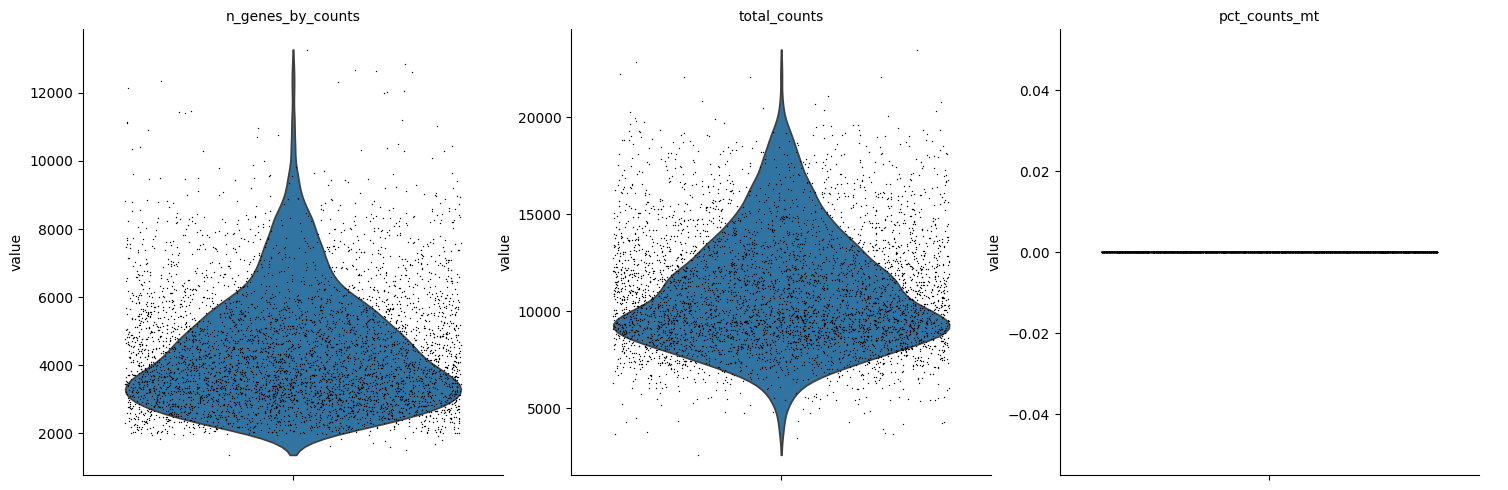

In [40]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

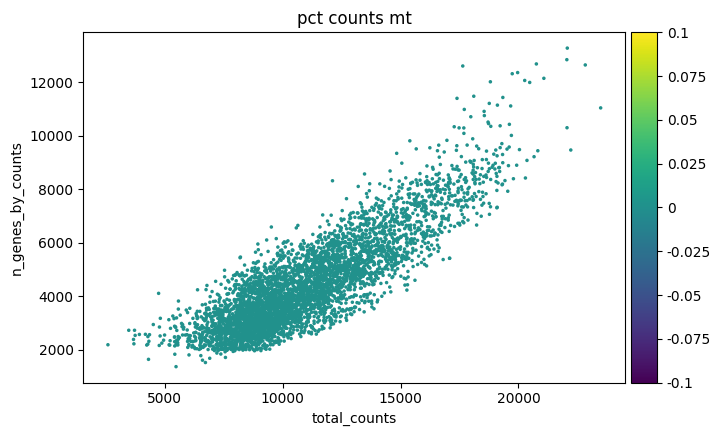

In [41]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

## Doublet Detection

##

# Normalization

Skipped. Already normalized.

# Feature Selection / Dimensionality Reduction

In [49]:
sc.pp.highly_variable_genes(adata, n_top_genes=5000)

extracting highly variable genes
    finished (0:00:03)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


In [50]:
adata

AnnData object with n_obs × n_vars = 4645 × 23677
    obs: 'tumor', 'malignant(1=no,2=yes,0=unresolved)', 'non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    layers: None (.X)

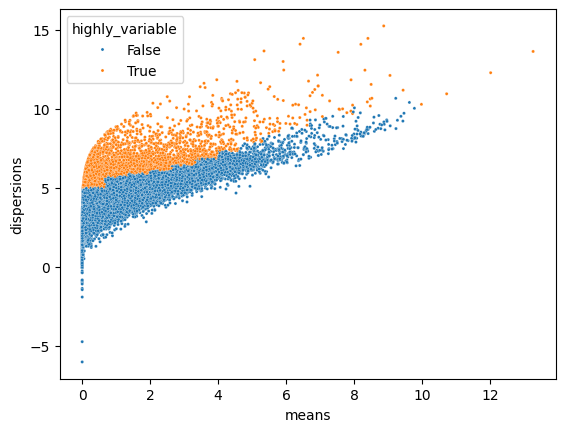

In [51]:
ax = sns.scatterplot(
    data=adata.var, x="means", y="dispersions", hue="highly_variable", s=5
)
plt.show()

Dimensionality reduction? maybe later

# Modeling

In [72]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification


In [54]:
X = adata.X.copy()

In [65]:
adata_mn = adata[adata.obs['malignant(1=no,2=yes,0=unresolved)'].isin([1,2])].copy()

In [66]:
adata_mn

AnnData object with n_obs × n_vars = 4513 × 23677
    obs: 'tumor', 'malignant(1=no,2=yes,0=unresolved)', 'non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    layers: None (.X)

In [67]:
X = adata_mn.X

In [70]:
y = adata_mn.obs['malignant(1=no,2=yes,0=unresolved)'].astype()

In [74]:
X

array([[0.    , 9.2172, 0.    , ..., 0.    , 2.6638, 0.    ],
       [0.    , 8.3745, 0.    , ..., 0.    , 6.9901, 0.    ],
       [0.    , 9.313 , 2.1263, ..., 3.8777, 1.6126, 0.    ],
       ...,
       [0.    , 7.0958, 0.    , ..., 0.    , 1.9615, 0.    ],
       [0.    , 3.997 , 0.    , ..., 0.    , 7.1918, 0.    ],
       [0.    , 3.9897, 0.    , ..., 5.2398, 6.1588, 0.    ]],
      dtype=float32)

In [75]:
y

Cy72_CD45_H02_S758_comb         1.0
CY58_1_CD45_B02_S974_comb       1.0
Cy71_CD45_D08_S524_comb         2.0
Cy81_FNA_CD45_B01_S301_comb     2.0
Cy80_II_CD45_B07_S883_comb      2.0
                               ... 
CY75_1_CD45_CD8_7__S223_comb    1.0
CY75_1_CD45_CD8_1__S65_comb     1.0
CY75_1_CD45_CD8_1__S93_comb     1.0
CY75_1_CD45_CD8_1__S76_comb     1.0
CY75_1_CD45_CD8_7__S274_comb    1.0
Name: malignant(1=no,2=yes,0=unresolved), Length: 4513, dtype: object

In [73]:
clf = RandomForestClassifier(max_depth=2, random_state=0)
clf.fit(X, y)

ValueError: Unknown label type: unknown. Maybe you are trying to fit a classifier, which expects discrete classes on a regression target with continuous values.

# Evaluation